# Chapter 6: Learning Best Practices for Model Evaluation and Hyperparameter Tuning - Part 1
## Streamlining workflows with pipelines

## Load the Breast Cancer Wisconsin dataset

In [1]:
import pandas as pd

df = pd.read_csv('https://archive.ics.uci.edu/ml/'
                 'machine-learning-databases'
                 '/breast-cancer-wisconsin/wdbc.data', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
df.shape

(569, 32)

### Create class response and check encoding transformation

In [3]:
from sklearn.preprocessing import LabelEncoder

X = df.loc[:, 2:].values
y = df.loc[:, 1].values
le = LabelEncoder()
y = le.fit_transform(y)
le.classes_

array(['B', 'M'], dtype=object)

In [ ]:
le.transform(['M', 'B']) # Check the numerical encoding of the original class labels

array([1, 0])

### Split into training- and testdatasets

In [4]:
from sklearn.model_selection import train_test_split

[X_train, X_test, y_train, y_test] = \
    train_test_split(X, y,
                     test_size=0.20,
                     stratify=y,
                     random_state=1)
X_train.shape[0] # The number of samples in the traning dataset.

455

## How to use the ["Pipeline" in scikit learn](https://scikit-learn.org/stable/modules/compose.html#pipeline)
Import the modelling building blocks and "make_pipeline".
Below we create a simple pipelining example:

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model  import LogisticRegression
from sklearn.pipeline      import make_pipeline

# Simple trainig data pipeline
pipe_lr = make_pipeline(StandardScaler(),    # Scaling of input features
                        PCA(n_components=2), # Compression into principal components
                        LogisticRegression(random_state=1)) # Fit Logistic Regression with standard parameters
pipe_lr

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",2
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'au

### Train model and predict test data:

In [7]:
# Train all parts of the pipeline using all .fit() and .transform() automatically
pipe_lr.fit(X_train, y_train)

# Predict through the .transforms() and .predict()
y_pred = pipe_lr.predict(X_test)
print('Test Accuracy: %.3f' % pipe_lr.score(X_test, y_test))

Test Accuracy: 0.956


### Check out 1: Copy/paste, then:
- switch LR with SVM
- change or remove the PCA feature extraction
- remove the standard scaling

In [8]:
from sklearn.svm import SVC
# Remember C parameter in SVC
pipe_svm = make_pipeline(StandardScaler(),    # Scaling of input features
                        PCA(n_components=5), # Compression into principal components
                        SVC(C=1, random_state=1)) # Fit Support Vector Classifier with standard parameters
pipe_svm

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('pca', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",5
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'au

In [9]:
pipe_svm.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()),
  ('pca', PCA(n_components=5)),
  ('svc', SVC(C=1, random_state=1))],
 'transform_input': None,
 'verbose': False,
 'standardscaler': StandardScaler(),
 'pca': PCA(n_components=5),
 'svc': SVC(C=1, random_state=1),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'pca__copy': True,
 'pca__iterated_power': 'auto',
 'pca__n_components': 5,
 'pca__n_oversamples': 10,
 'pca__power_iteration_normalizer': 'auto',
 'pca__random_state': None,
 'pca__svd_solver': 'auto',
 'pca__tol': 0.0,
 'pca__whiten': False,
 'svc__C': 1,
 'svc__break_ties': False,
 'svc__cache_size': 200,
 'svc__class_weight': None,
 'svc__coef0': 0.0,
 'svc__decision_function_shape': 'ovr',
 'svc__degree': 3,
 'svc__gamma': 'scale',
 'svc__kernel': 'rbf',
 'svc__max_iter': -1,
 'svc__probability': False,
 'svc__random_state': 1,
 'svc__shrinking': True,
 'svc__tol': 0.001,
 'svc__verbose': False}

In [9]:
pipe_svm.named_steps['svc']

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",False
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


Back to presentation

# Using k-fold cross validation to assess model performance
### [Cross-validation iterators](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators)

### Schematic illustration of 3-fold CV with 10 samples:

In [11]:
import numpy as np
from sklearn.model_selection import KFold

X = np.zeros([10,1])
k = 3 # The number of crossvalidation splits
kfold = KFold(n_splits=k)

for train, test in kfold.split(X): # Uses dimension 0 of X to define sizes, then splits thrice
    print("%s %s" % (train, test))

[4 5 6 7 8 9] [0 1 2 3]
[0 1 2 3 7 8 9] [4 5 6]
[0 1 2 3 4 5 6] [7 8 9]


In [ ]:
# Try shuffle = True, random_state ...

## [Stratified cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#stratified-k-fold)
The idea is that each CV-segment should contain approximately the same percentage of samples of each target class as in the complete dataset:

In [12]:
from sklearn.model_selection import StratifiedKFold

# Two classes to be represented in each split
y = np.hstack([np.zeros(4),np.ones(6)])
kfold = StratifiedKFold(n_splits=3).split(X, y) # Extra argument to split

for k, (train, test) in enumerate(kfold):
    print("%s %s" % (train, test))

[2 3 6 7 8 9] [0 1 4 5]
[0 1 3 4 5 8 9] [2 6 7]
[0 1 2 4 5 6 7] [3 8 9]


In [ ]:
# Try shuffle = True, random_state ...

### Random splits without and with predifined groups
Shuffle as many times as needed.

In [ ]:
from sklearn.model_selection import ShuffleSplit # i.e., Shuffle and Split

X = [0.1, 0.2, 2.2, 2.4, 2.3, 4.55, 5.8, 0.001]
y = ["a", "b", "b", "b", "c", "c", "c", "a"]
ss = ShuffleSplit(n_splits=6, # Number of times a train-test split should be done
                  test_size=0.25, random_state=0) # Change us!
for train, test in ss.split(X, y):
    print("%s %s" % (train, test))

[1 7 3 0 5 4] [6 2]
[3 7 0 4 2 5] [1 6]
[3 4 7 0 6 1] [5 2]
[6 7 3 4 1 0] [2 5]
[1 6 3 2 0 7] [4 5]
[7 1 0 6 3 5] [4 2]


Keep groups of replicate measurements (or similar) together.

In [14]:
import numpy as np
from sklearn.model_selection import GroupShuffleSplit

# Example data
X = np.arange(8).reshape(-1, 1)  # 8 samples
y = np.array([0, 1, 0, 1, 0, 1, 0, 1])  # 8 samples
segments = [1, 1, 2, 2, 3, 3, 4, 4]  # 8 groups (same length as X and y)

# GroupShuffleSplit example
gss = GroupShuffleSplit(n_splits=5, test_size=0.25, random_state=1)

for train_idx, test_idx in gss.split(X, y, groups=segments):
    print("TRAIN:", train_idx, "TEST:", test_idx)


TRAIN: [0 1 2 3 4 5] TEST: [6 7]
TRAIN: [2 3 4 5 6 7] TEST: [0 1]
TRAIN: [0 1 2 3 4 5] TEST: [6 7]
TRAIN: [0 1 2 3 6 7] TEST: [4 5]
TRAIN: [0 1 2 3 4 5] TEST: [6 7]


### Leave P groups out
For instance, keep groups of replicate measurements together

In [15]:
from sklearn.model_selection import LeavePGroupsOut
import numpy as np

lpgo = LeavePGroupsOut(n_groups=2)
X = np.arange(18)
y = [1, 1, 2, 2, 3, 3, 1, 1, 2, 2, 3, 3, 1, 1, 2, 2, 3, 3]
segments = [1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 7, 8, 8, 9, 9]
for train, test in lpgo.split(X, y, groups=segments):
    print("%s %s" % (train, test))

[ 4  5  6  7  8  9 10 11 12 13 14 15 16 17] [0 1 2 3]
[ 2  3  6  7  8  9 10 11 12 13 14 15 16 17] [0 1 4 5]
[ 2  3  4  5  8  9 10 11 12 13 14 15 16 17] [0 1 6 7]
[ 2  3  4  5  6  7 10 11 12 13 14 15 16 17] [0 1 8 9]
[ 2  3  4  5  6  7  8  9 12 13 14 15 16 17] [ 0  1 10 11]
[ 2  3  4  5  6  7  8  9 10 11 14 15 16 17] [ 0  1 12 13]
[ 2  3  4  5  6  7  8  9 10 11 12 13 16 17] [ 0  1 14 15]
[ 2  3  4  5  6  7  8  9 10 11 12 13 14 15] [ 0  1 16 17]
[ 0  1  6  7  8  9 10 11 12 13 14 15 16 17] [2 3 4 5]
[ 0  1  4  5  8  9 10 11 12 13 14 15 16 17] [2 3 6 7]
[ 0  1  4  5  6  7 10 11 12 13 14 15 16 17] [2 3 8 9]
[ 0  1  4  5  6  7  8  9 12 13 14 15 16 17] [ 2  3 10 11]
[ 0  1  4  5  6  7  8  9 10 11 14 15 16 17] [ 2  3 12 13]
[ 0  1  4  5  6  7  8  9 10 11 12 13 16 17] [ 2  3 14 15]
[ 0  1  4  5  6  7  8  9 10 11 12 13 14 15] [ 2  3 16 17]
[ 0  1  2  3  8  9 10 11 12 13 14 15 16 17] [4 5 6 7]
[ 0  1  2  3  6  7 10 11 12 13 14 15 16 17] [4 5 8 9]
[ 0  1  2  3  6  7  8  9 12 13 14 15 16 17] [ 4  5

### Application of stratified CV for the Wisconsin data

---



In [16]:
import numpy as np
from sklearn.model_selection import StratifiedKFold

# Make 10 stratified CV-splits:
kfold = StratifiedKFold(n_splits=10).split(X_train, y_train)


In [17]:
scores = []

# For each CV-split use pipeline from above to fit & score the train-/test-parts of each split
for k, (train, test) in enumerate(kfold):
    pipe_lr.fit(X_train[train], y_train[train])
    score = pipe_lr.score(X_train[test], y_train[test])
    scores.append(score) # Append the score-results of each CV-split
    print('Fold: %2d, Class dist.: %s, Acc: %.3f' % (k+1,
          np.bincount(y_train[train]), score))

print('\nCV accuracy: %.3f +/- %.3f' % (np.mean(scores), np.std(scores)))

Fold:  1, Class dist.: [256 153], Acc: 0.935
Fold:  2, Class dist.: [256 153], Acc: 0.935
Fold:  3, Class dist.: [256 153], Acc: 0.957
Fold:  4, Class dist.: [256 153], Acc: 0.957
Fold:  5, Class dist.: [256 153], Acc: 0.935
Fold:  6, Class dist.: [257 153], Acc: 0.956
Fold:  7, Class dist.: [257 153], Acc: 0.978
Fold:  8, Class dist.: [257 153], Acc: 0.933
Fold:  9, Class dist.: [257 153], Acc: 0.956
Fold: 10, Class dist.: [257 153], Acc: 0.956

CV accuracy: 0.950 +/- 0.014


### ... using the [cross-validation scorer](https://scikit-learn.org/stable/modules/cross_validation.html#computing-cross-validated-metrics)

In [30]:
from sklearn.model_selection import cross_val_score
# from sklearn.model_selection import LeaveOneOut

scores = cross_val_score(estimator=pipe_lr,
                         X=X_train,
                         y=y_train,
                         cv=10,
                         n_jobs=1)  # Distribute to processors/processes
print('CV accuracy scores: %s' % scores)
print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores), np.std(scores)))
# scikit-learn computes scores per segment instead of across all samples (as one would in statistics).
# Be careful with LOO or use cross_val_predict!

CV accuracy scores: [1.         0.97826087 1.         0.97826087 0.93478261 0.95555556
 0.97777778 0.97777778 1.         1.        ]
CV accuracy: 0.980 +/- 0.021


### Check out 2: Copy/paste from above & check out the cross-validation predictions:
- Try to exchange "cross_val_score" with "cross_val_predict"
- Calculate accuracy of all predictions
- Compare with previous result

In [ ]:
from sklearn.model_selection import cross_val_predict
#
#
#
#
#
#

Back to presentation

# Learning curves
Assessing bias and variance problems.  
We will use a pipeline and see how training and test scores change with the amount of data used for modelling.

In [19]:
np.linspace(0.1, 1.0, 10)

array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ])

In [25]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Simple pipeline with variable scaling and L2 penalized Logistic Regression
# Estimate learning curves using increasing proportions
# Simple pipeline with scaling and L2 penalized Logistic Regression
pipe_lr = make_pipeline(StandardScaler(),
                        LogisticRegression(solver='lbfgs', max_iter=200, penalty='l2', random_state=1))
# Recall : the L2 penalty in LR has a regularization parameter C which
# is the inverse of the regularization strength.

# Estimate learning curves using increasing proportions
# of the available data included as training samples:
[train_sizes, train_scores, test_scores] =\
                learning_curve(estimator=pipe_lr,
                               X = X_train,
                               y = y_train,
                               train_sizes=np.linspace(0.1, 1.0, 10),
                               cv= 10, # Stratified KFold by default
                               n_jobs=1)

print("#Samples:", train_sizes)
print("Output size:", train_scores.shape)

#Samples: [ 40  81 122 163 204 245 286 327 368 409]
Output size: (10, 10)


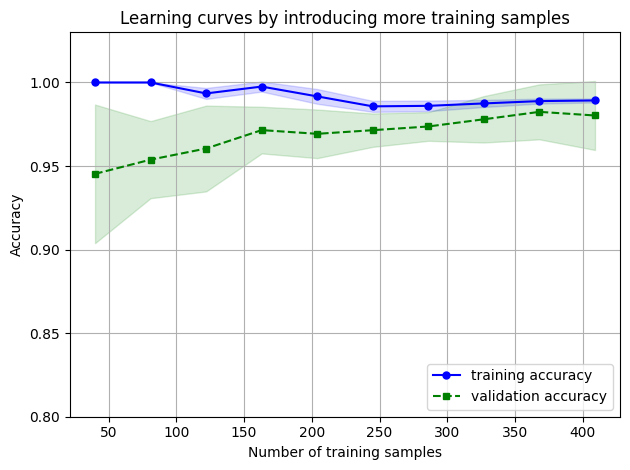

In [26]:
# Calculate learning curves for training- and test sets:
train_mean = np.mean(train_scores, axis = 1)   # Predict training data
train_std  = np.std(train_scores,  axis = 1)
test_mean  = np.mean(test_scores,  axis = 1)   # Cross-validation
test_std   = np.std(test_scores,   axis = 1)

plt.plot(train_sizes, train_mean,
         color='blue', marker='o',
         markersize=5, label='training accuracy')

plt.fill_between(train_sizes,
                 train_mean + train_std,
                 train_mean - train_std,
                 alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5,
         label='validation accuracy')

plt.fill_between(train_sizes,
                 test_mean + test_std,
                 test_mean - test_std,
                 alpha=0.15, color='green')

plt.grid()
plt.xlabel('Number of training samples')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.title('Learning curves by introducing more training samples')
plt.ylim([0.8, 1.03])
plt.tight_layout()
plt.show()

## Validation curves
Addressing over- and underfitting

In [27]:
np.logspace(-3,2,6)

array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02])

In [28]:
from sklearn.model_selection import validation_curve

# Reuse pipeline, but vary model parameter instead of sample size
param_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
[train_scores, test_scores] = validation_curve(
                estimator=pipe_lr,
                X=X_train,
                y=y_train,
                param_name='logisticregression__C', # The parameter to vary
                param_range=param_range,            # ... and its values
                cv=10) # Stratified KFold by default
print(pipe_lr)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(max_iter=200, random_state=1))])


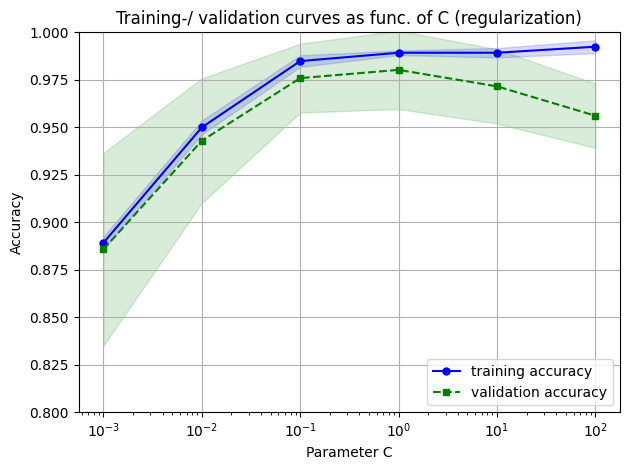

In [29]:
# Calculate validation curves for training and test sets
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

plt.plot(param_range, train_mean,
         color='blue', marker='o',
         markersize=5, label='training accuracy')

plt.fill_between(param_range, train_mean + train_std,
                 train_mean - train_std, alpha=0.15,
                 color='blue')

plt.plot(param_range, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5,
         label='validation accuracy')

plt.fill_between(param_range,
                 test_mean + test_std,
                 test_mean - test_std,
                 alpha=0.15, color='green')

plt.grid()
plt.xscale('log')
plt.legend(loc='lower right')
plt.xlabel('Parameter C')
plt.ylabel('Accuracy')
plt.title('Training-/ validation curves as func. of C (regularization)')
plt.ylim([0.8, 1.0])
plt.tight_layout()
plt.show()